# 08 - EDA dữ liệu mua sắm siêu thị (Online Retail)

Mục tiêu: bài tập thực hành 2 (mục 1.2.3), EDA đầy đủ: làm sạch, phân bố, theo quốc gia, sản phẩm, thời gian và khách hàng.

## 1. Load data và kiểm tra chất lượng

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'figures'
REPORT_DIR = ROOT / 'reports'
FIG_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


def doc_csv(path, **kwargs):
    return pd.read_csv(path, sep=None, engine='python', **kwargs)


def can_file(*names):
    for name in names:
        if (DATA_DIR / name).exists():
            return DATA_DIR / name
    raise FileNotFoundError(f'Không thấy {names} trong {DATA_DIR}. Xem data/README.txt để biết cách tải.')


def mo_ta_thong_ke(frame):
    rows = {}
    for col in frame.select_dtypes(include=np.number).columns:
        s = frame[col].dropna()
        if s.empty:
            continue
        q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
        iqr = q3 - q1
        rows[col] = {
            'count': s.size, 'mean': s.mean(), 'median': s.median(), 'mode': s.mode().iloc[0],
            'variance': s.var(), 'std': s.std(), 'min': s.min(), 'max': s.max(), 'range': s.max() - s.min(),
            'P60': np.percentile(s, 60), 'Q1': q1, 'Q2': q2, 'Q3': q3, 'IQR': iqr,
            'skew': s.skew(), 'kurtosis': s.kurt(),
            'so_outlier_iqr': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(rows).T


def kiem_tra_chat_luong(frame, ten):
    print(f'=== {ten} ===')
    print('Shape:', frame.shape)
    print('Số dòng trùng lặp:', int(frame.duplicated().sum()))
    thieu = frame.isna().sum()
    print('Giá trị thiếu theo cột:')
    print(thieu[thieu > 0] if thieu.sum() else '  Không có giá trị thiếu')


def luoi(cols, ve, ncols=4, size=(4.5, 3.2)):
    cols = list(cols)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        ve(ax, col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    return fig


def luu_hinh(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def cap_nhat_summary(notebook, dataset, frame):
    tk = mo_ta_thong_ke(frame)
    row = {
        'notebook': notebook, 'dataset': dataset, 'rows': len(frame), 'cols': frame.shape[1],
        'numeric_cols': len(frame.select_dtypes(include=np.number).columns),
        'categorical_cols': len(frame.select_dtypes(exclude=np.number).columns),
        'missing_cells': int(frame.isna().sum().sum()), 'duplicate_rows': int(frame.duplicated().sum()),
        'outlier_cells_iqr': int(tk['so_outlier_iqr'].sum()) if len(tk) else 0,
    }
    path = FIG_DIR / 'results_summary.csv'
    old = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=list(row))
    old = old[old['notebook'] != notebook]
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print('Đã cập nhật:', path.name)

retail = pd.read_csv(can_file('OnlineRetail.csv', 'data.csv'), encoding='ISO-8859-1')
kiem_tra_chat_luong(retail, 'Online Retail')
display(retail.head())

=== Online Retail ===
Shape: (541909, 8)
Số dòng trùng lặp: 5268
Giá trị thiếu theo cột:
Description      1454
CustomerID     135080
dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## 2. Làm sạch

Loại dòng trùng lặp, đơn hủy (`InvoiceNo` bắt đầu bằng C), dòng có `Quantity` hoặc `UnitPrice` không dương. `CustomerID` thiếu được giữ cho phân tích sản phẩm/thời gian và chỉ loại khi phân tích theo khách hàng.

In [2]:
n0 = len(retail)
retail = retail.drop_duplicates().copy()
retail['InvoiceNo'] = retail['InvoiceNo'].astype(str)
huy = retail['InvoiceNo'].str.startswith('C')
print('Số dòng đơn hủy:', int(huy.sum()), '| Quantity <= 0:', int((retail['Quantity'] <= 0).sum()), '| UnitPrice <= 0:', int((retail['UnitPrice'] <= 0).sum()))
retail = retail[~huy & (retail['Quantity'] > 0) & (retail['UnitPrice'] > 0)].copy()
print(f'Số dòng: {n0} -> {len(retail)}')

retail['InvoiceDate'] = pd.to_datetime(retail['InvoiceDate'])
retail['Revenue'] = retail['Quantity'] * retail['UnitPrice']
retail['Month'] = retail['InvoiceDate'].dt.to_period('M').astype(str)
retail['Hour'] = retail['InvoiceDate'].dt.hour
thu = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
retail['Weekday'] = pd.Categorical(retail['InvoiceDate'].dt.day_name(), categories=thu, ordered=True)
display(mo_ta_thong_ke(retail[['Quantity', 'UnitPrice', 'Revenue']]).round(2))
print('Khoảng thời gian:', retail['InvoiceDate'].min(), '->', retail['InvoiceDate'].max())

Số dòng đơn hủy: 9251 | Quantity <= 0: 10587 | UnitPrice <= 0: 2512
Số dòng: 541909 -> 524878


,count,mean,median,mode,variance,std,min,max,range,P60,Q1,Q2,Q3,IQR,skew,kurtosis,so_outlier_iqr
Quantity,524878.0,10.62,4.00,1.00,24423.45,156.28,1.0,80995.00,80994.00,6.00,1.00,4.00,11.00,10.00,469.54,234228.70,27111.0
UnitPrice,524878.0,3.92,2.08,1.25,1302.71,36.09,0.0,13541.33,13541.33,2.55,1.25,2.08,4.13,2.88,205.09,61873.72,37827.0
Revenue,524878.0,20.28,9.92,15.00,73817.39,271.69,0.0,168469.60,168469.60,13.20,3.90,9.92,17.70,13.80,504.23,294741.14,42624.0


Khoảng thời gian: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


## 3. Phân bố của Quantity, UnitPrice, Revenue

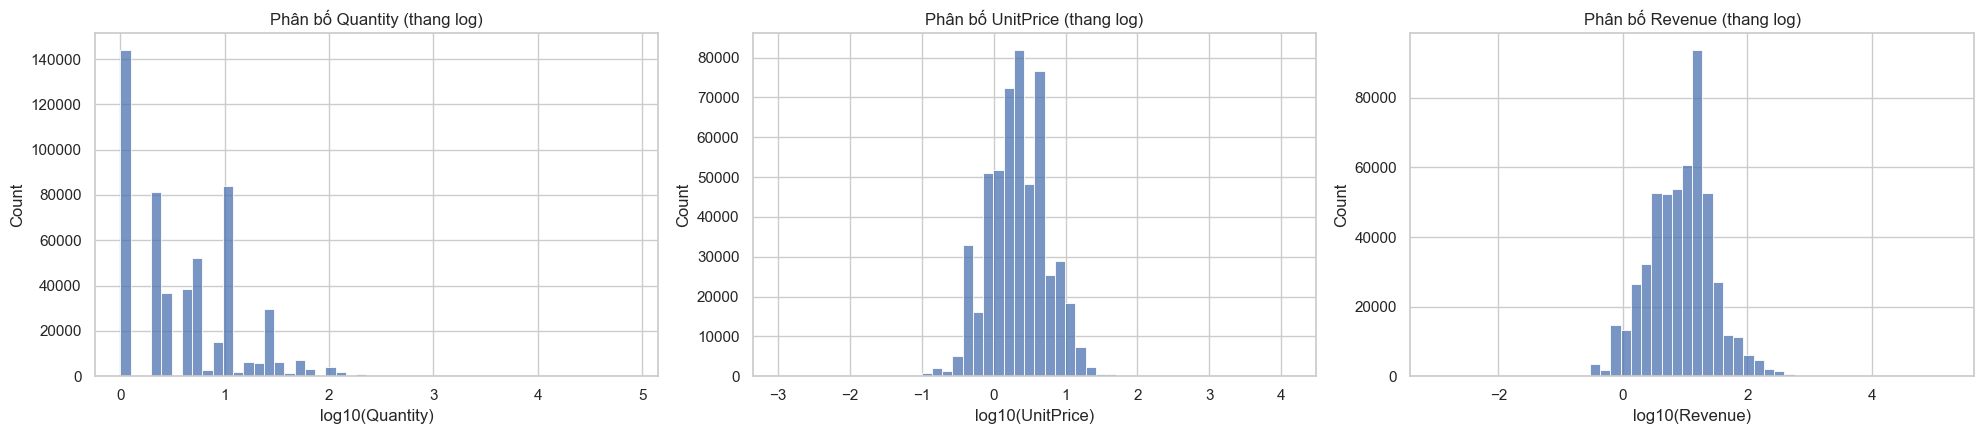

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for ax, c in zip(axes, ['Quantity', 'UnitPrice', 'Revenue']):
    sns.histplot(np.log10(retail[c]), bins=50, ax=ax); ax.set_xlabel(f'log10({c})'); ax.set_title(f'Phân bố {c} (thang log)')
luu_hinh('08_retail_distributions')

## 4. Theo quốc gia và sản phẩm

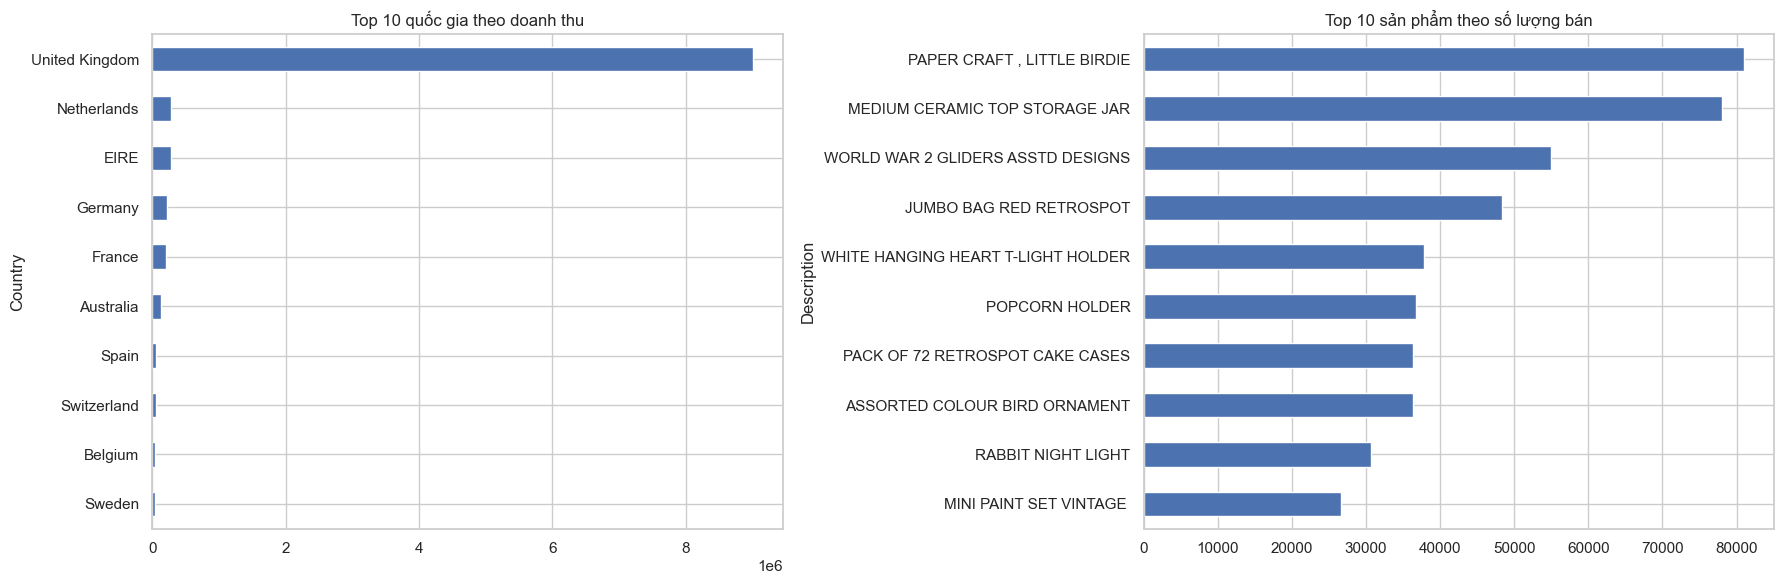

Quốc gia dẫn đầu chiếm 84.6% tổng doanh thu


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
top_ctry = retail.groupby('Country')['Revenue'].sum().nlargest(10).sort_values()
top_ctry.plot.barh(ax=axes[0]); axes[0].set_title('Top 10 quốc gia theo doanh thu')
top_prod = retail.groupby('Description')['Quantity'].sum().nlargest(10).sort_values()
top_prod.plot.barh(ax=axes[1]); axes[1].set_title('Top 10 sản phẩm theo số lượng bán')
luu_hinh('08_retail_top_country_product')
ty_trong = top_ctry.sort_values(ascending=False).iloc[0] / retail['Revenue'].sum() * 100
print(f'Quốc gia dẫn đầu chiếm {ty_trong:.1f}% tổng doanh thu')

## 5. Theo thời gian

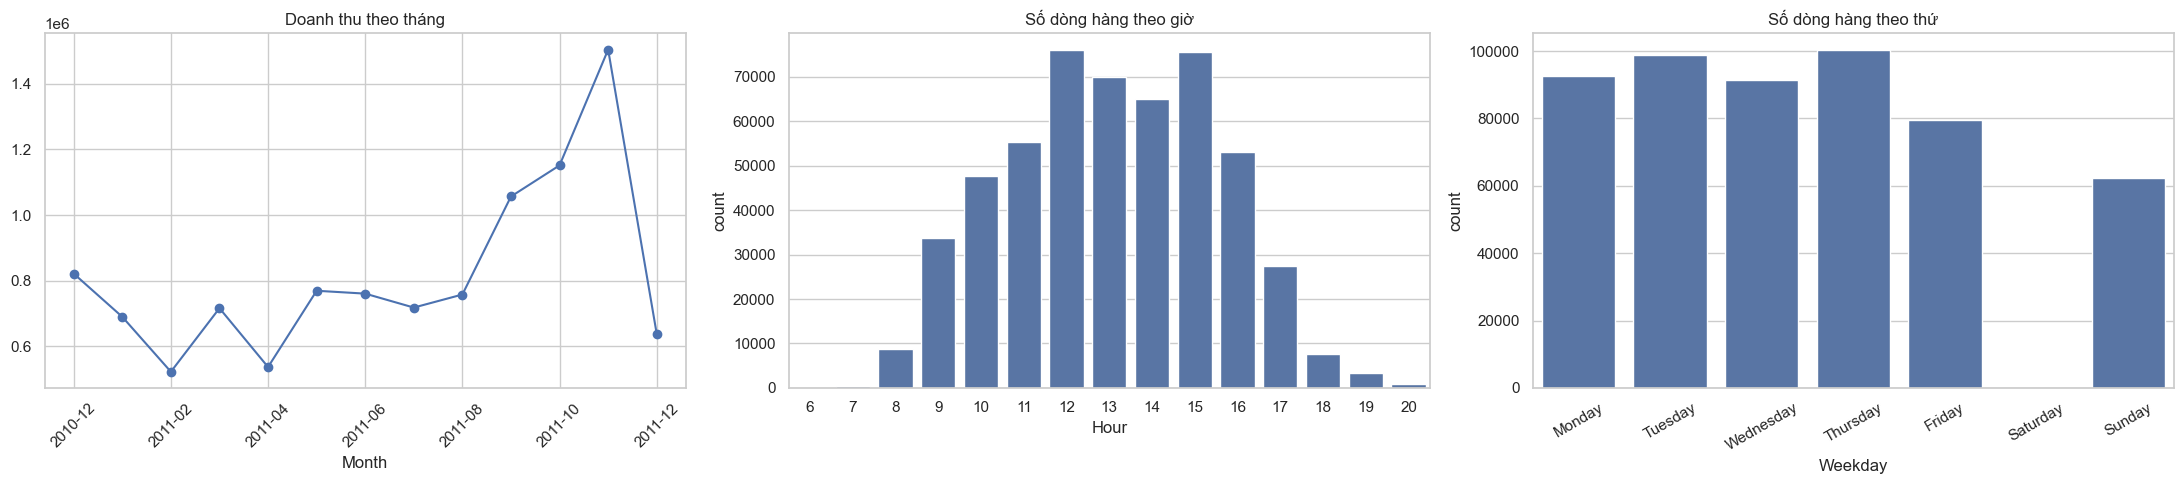

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(22, 5))
retail.groupby('Month')['Revenue'].sum().plot(marker='o', ax=axes[0]); axes[0].set_title('Doanh thu theo tháng'); axes[0].tick_params(axis='x', rotation=45)
sns.countplot(data=retail, x='Hour', ax=axes[1]); axes[1].set_title('Số dòng hàng theo giờ')
sns.countplot(data=retail, x='Weekday', ax=axes[2]); axes[2].set_title('Số dòng hàng theo thứ'); axes[2].tick_params(axis='x', rotation=30)
luu_hinh('08_retail_time')

## 6. Khách hàng và quan hệ hai biến

Số khách hàng: 4338 | dòng thiếu CustomerID: 132186


,so_don,tong_chi
count,4338.00,4338.00
mean,4.27,2048.69
std,7.70,8985.23
min,1.00,3.75
25%,1.00,306.48
50%,2.00,668.57
75%,5.00,1660.60
max,209.00,280206.02


10 khách hàng chi nhiều nhất chiếm 17.3% doanh thu có CustomerID


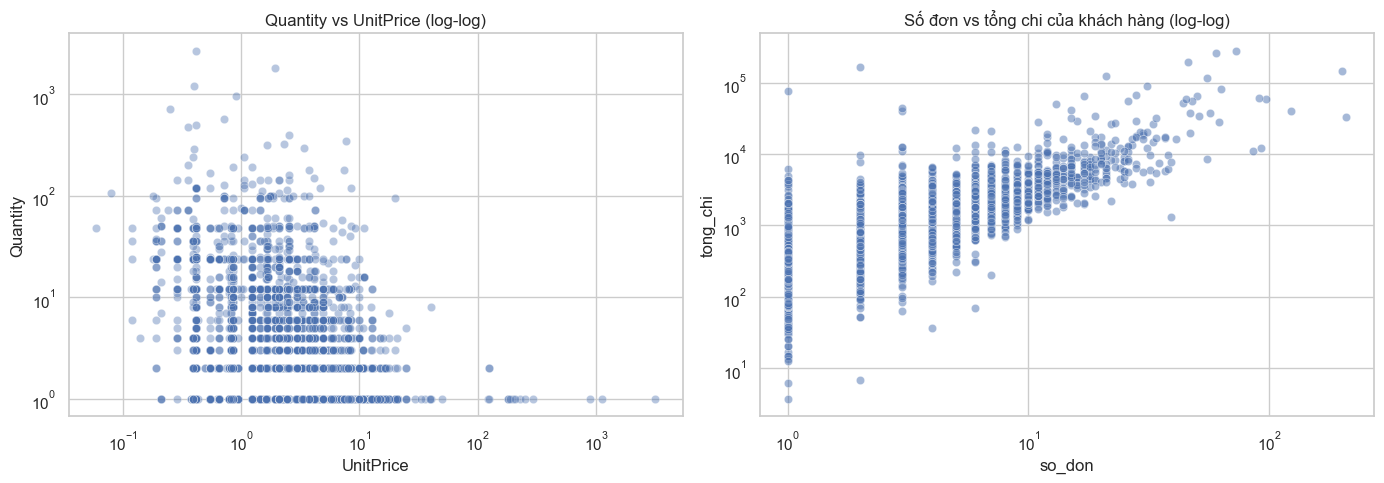

Đã cập nhật: results_summary.csv


In [6]:
kh = retail.dropna(subset=['CustomerID']).groupby('CustomerID').agg(so_don=('InvoiceNo', 'nunique'), tong_chi=('Revenue', 'sum'))
print('Số khách hàng:', len(kh), '| dòng thiếu CustomerID:', int(retail['CustomerID'].isna().sum()))
display(kh.describe().round(2))
top10_kh = kh['tong_chi'].nlargest(10).sum() / kh['tong_chi'].sum() * 100
print(f'10 khách hàng chi nhiều nhất chiếm {top10_kh:.1f}% doanh thu có CustomerID')

sample = retail.sample(min(5000, len(retail)), random_state=24)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=sample, x='UnitPrice', y='Quantity', alpha=0.4, ax=axes[0])
axes[0].set_xscale('log'); axes[0].set_yscale('log'); axes[0].set_title('Quantity vs UnitPrice (log-log)')
sns.scatterplot(data=kh, x='so_don', y='tong_chi', alpha=0.5, ax=axes[1])
axes[1].set_xscale('log'); axes[1].set_yscale('log'); axes[1].set_title('Số đơn vs tổng chi của khách hàng (log-log)')
luu_hinh('08_retail_bivariate')
cap_nhat_summary('08_online_retail_eda', 'OnlineRetail.csv (sau làm sạch)', retail[['Quantity', 'UnitPrice', 'Revenue', 'CustomerID']])

## 7. Nhận xét

Quantity, UnitPrice và Revenue lệch phải rất mạnh nên cần thang log khi trực quan hóa. Doanh thu tập trung vào một vài quốc gia, một nhóm nhỏ khách hàng và có mùa vụ theo tháng; các dòng thiếu `CustomerID` không dùng được cho phân tích theo khách hàng. Đơn hủy và số lượng/giá không dương được loại có chủ đích, nếu muốn phân tích trả hàng thì cần giữ lại và xử lý riêng.